# FIEP — Detecção de contaminação em superfícies por voltametria e aprendizado de máquina

Notebook da pipeline do projeto: do arquivo do potenciostato até o modelo escolhido.

| Etapa | Objetivo específico do projeto |
|---|---|
| 1. Dados → banco SQLite (lote de `.nox` + planilha) | OE2 aquisição · OE4 banco de dados |
| 2. Controle de qualidade automático | OE2 · OE3 |
| 3. Exploração: estágios do sensor e curva de diferença | OE1 · OE3 |
| 4. Experimentos: representações × modelos (inclui SISSO) | OE3 · OE5 |
| 5. Modelo escolhido: teste, interpretação, regressão da carga | OE5 |
| 6. Previsão de uma coleta nova (o mesmo que a API faz) | OE6 |

**Como usar com os dados reais** (detalhes em `dados/README.md`):

- coloque os `.nox` e a planilha de metadados **direto em `dados/`**: as amostras são divididas em
  **50% treino, 25% validação e 25% teste** (por amostra, estratificado pela classe — Hastie et al.,
  *The Elements of Statistical Learning*, seção 7.2; proporções em `[divisao]` de `configs/default.toml`);
- o que estiver em `dados/treino/`, `dados/validacao/` ou `dados/teste/` vai inteiro para aquele conjunto,
  somado à parte sorteada (ex.: uma coleta de outra empresa em `dados/teste/`).

Enquanto não houver dados, o notebook usa o conjunto de demonstração `dados/exemplo_case/`.

Rode a partir da **raiz do repositório** (`jupyter notebook notebook/fiep.ipynb` ou abra no VS Code/PyCharm).

In [1]:
import os, sys
from pathlib import Path

# o notebook fica em notebook/: trabalhar a partir da raiz do repositório
RAIZ = Path.cwd() if (Path.cwd() / "fiep").exists() else Path.cwd().parent
os.chdir(RAIZ)
sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

from fiep import __version__, db
from fiep.config import load_config
from fiep.divisao import CONJUNTOS, RESERVADAS, de_pastas
from fiep.ingest import ingerir, juntar, tem_dados
from fiep.qc import avaliar
from fiep.figuras import _plt, CLASSE, NOME_CLASSE, TINTA_2

_plt()                                   # estilo das figuras (mesmo do artigo)
pd.set_option("display.max_columns", 40)

DADOS = Path("dados")
BANCO = "dados/fiep.db"
RAPIDO = False        # True: menos variantes/modelos (alguns minutos a menos)

cfg = load_config("configs/default.toml")
divisao = de_pastas(DADOS, cfg)          # treino / validação / teste (regra em fiep/divisao.py)
print(f"fiep {__version__}\n" + divisao.descricao().replace(" — ", "\n").replace("; ", "\n"))

Sem dados em dados: usando dados/exemplo_case (demonstração).


fiep 0.1.0
divisão 50/25/25 por amostra, estratificada pela classe
treino: 100 amostras (100 sorteadas de dados/)
validacao: 50 amostras (50 sorteadas de dados/)
teste: 50 amostras (50 sorteadas de dados/)


## 1. Dados → banco de dados

Para `.nox`, o primeiro passo é gerar a planilha de metadados do lote (`fiep planilha`), que já
lista os arquivos, a técnica e o resultado do controle de qualidade; a equipe preenche amostra,
réplica, estágio do sensor e rótulo. Depois, a importação grava tudo no banco SQLite, registrando
cada arquivo pelo hash (reimportar não duplica).

In [2]:
from fiep.planilha import gerar_planilha

# pastas com dados: soltos em dados/ (a sortear) e as pastas de cada conjunto
partes = [(None, DADOS, RESERVADAS)] if tem_dados(DADOS, RESERVADAS) else []
partes += [(k, DADOS / k, ()) for k in CONJUNTOS if tem_dados(DADOS / k)]
if not partes:                                   # demonstração
    partes = [(None, DADOS / "exemplo_case", ())]
for conjunto, pasta, _ in partes:
    if conjunto and any(pasta.rglob("*.nox")):
        destino, novos = gerar_planilha(pasta, cfg=cfg)
        print(f"Planilha {destino}: {novos} arquivo(s) novo(s) — preencha antes de treinar")

con = db.conectar(BANCO, dados_exemplo=False)   # o notebook importa os próprios dados
for conjunto, pasta, excluir in partes:
    d = ingerir(pasta, excluir=excluir)
    d.medicoes["conjunto"] = conjunto
    db.importar(con, d, origem=str(pasta), conjunto=conjunto)
    db.gravar_qc(con, avaliar(d.medicoes, d.pontos, cfg))

# exploração (seções 2 e 3) só com treino + validação: o teste fica guardado para o fim
ds = juntar(divisao.treino, divisao.validacao)
db.resumo(con)

0003: dados de exemplo pulados


,item,total
0,empresas,0
1,coletas,1
2,amostras,200
3,amostras contaminadas,150
4,amostras sem rótulo,0
5,medições,1800
6,pontos,235800
7,plaqueamentos,600
8,réplicas com os 3 estágios aprovados,502
9,medições reprovadas no QC (FAIL),26


In [3]:
# Réplicas: cada eletrodo precisa dos três estágios aprovados para entrar no modelo
rep = db.sql(con, "SELECT * FROM v_replicatas")
print(f"{(rep.n_aprovadas >= 3).sum()} de {len(rep)} réplicas completas")
db.sql(con, "SELECT target_bacterium, contamination_status, COUNT(*) AS amostras FROM amostras GROUP BY 1, 2")

502 de 600 réplicas completas


,target_bacterium,contamination_status,amostras
0,Escherichia coli,0,25
1,Escherichia coli,1,75
2,Staphylococcus aureus,0,25
3,Staphylococcus aureus,1,75


## 2. Controle de qualidade

Regras automáticas (`configs/default.toml`, seção `[qc]`): sobrecarga de corrente, potencial medido
longe do aplicado (só `.nox`), poucos pontos, pontos inválidos e corrente fora do padrão do lote.
O resultado é combinado com o `qc_flag` da planilha (vale o mais restritivo).

In [4]:
qc = db.sql(con, "SELECT * FROM v_qc_atual")
qc = qc[qc.measurement_id.isin(set(ds.medicoes.measurement_id))]
display(pd.crosstab(qc["qc_planilha"].fillna("—"), qc["qc_auto"], margins=True, margins_name="total"))
motivos = qc.loc[qc.qc_final != "PASS", "qc_motivos"].fillna("marcado na planilha").value_counts()
motivos.head(10)

qc_auto,PASS,total
qc_planilha,,
FAIL,18,18
PASS,1270,1270
REVIEW,62,62
total,1350,1350


qc_motivos
marcado na planilha    80
Name: count, dtype: int64

## 3. Exploração: os três estágios do sensor

O sinal de interesse é a **mudança** entre estágios no mesmo eletrodo: a hibridização do alvo com a
sonda de captura dificulta a transferência de carga do ferri/ferrocianeto e reduz a corrente de pico.

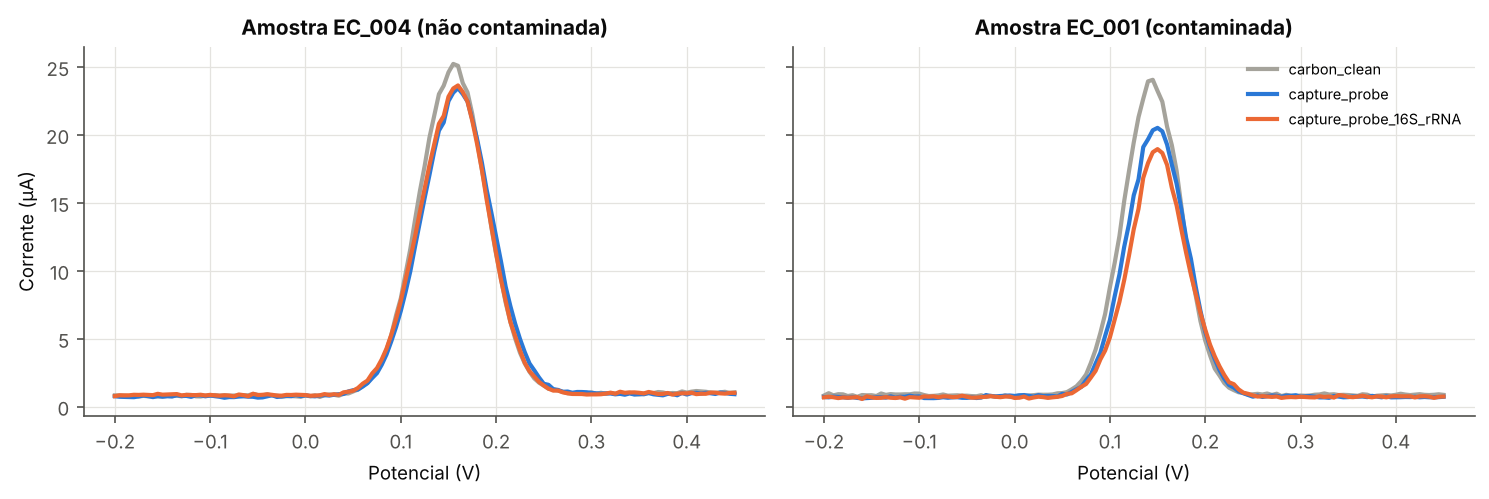

In [5]:
from fiep.preprocess import curvas_por_medicao, inferir_grade, para_matriz

ok = set(qc.loc[qc.qc_final == "PASS", "measurement_id"])
med = ds.medicoes[ds.medicoes.measurement_id.isin(ok)]
exemplo = {c: med[(med.contamination_status == c)].groupby(["sample_id", "replicate_id"]).filter(lambda g: len(g) == 3)
           .head(3) for c in (0, 1)}
estagios = cfg["dados"]["estagios"]
cores = {e: c for e, c in zip(estagios, ["#a5a39b", "#2a78d6", "#eb6834"])}

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, c in zip(axes, (0, 1)):
    for _, r in exemplo[c].iterrows():
        p = ds.pontos[ds.pontos.measurement_id == r.measurement_id].sort_values("potential_v")
        ax.plot(p.potential_v, p.current_ua, color=cores[r.sensor_state], label=r.sensor_state)
    ax.set_title(f"Amostra {exemplo[c].sample_id.iloc[0]} ({NOME_CLASSE[c]})")
    ax.set_xlabel("Potencial (V)")
axes[0].set_ylabel("Corrente (µA)")
axes[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

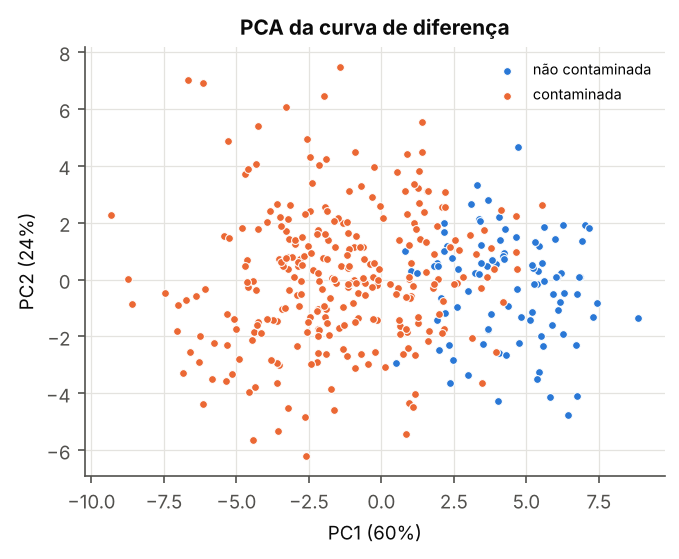

In [6]:
# PCA da curva de diferença (último − penúltimo estágio): as classes se separam?
from sklearn.decomposition import PCA
from fiep.features import tabela_features

curvas = curvas_por_medicao(ds.pontos, ok, cfg)
matriz = para_matriz(curvas, inferir_grade(curvas, cfg), cfg)
tab = tabela_features(matriz, ds.medicoes, cfg).dropna(subset=["contamination_status"])
D = tab[[c for c in tab.columns if c.startswith("D_")]].fillna(0)
pcs = PCA(n_components=2).fit(D)
z = pcs.transform(D)

fig, ax = plt.subplots(figsize=(4.6, 3.8))
for c in (0, 1):
    m = tab.contamination_status.to_numpy() == c
    ax.scatter(z[m, 0], z[m, 1], s=14, color=CLASSE[c], edgecolor="white", linewidth=0.5, label=NOME_CLASSE[c])
ax.set_xlabel(f"PC1 ({pcs.explained_variance_ratio_[0]:.0%})"); ax.set_ylabel(f"PC2 ({pcs.explained_variance_ratio_[1]:.0%})")
ax.set_title("PCA da curva de diferença"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

## 4. Experimentos: representações × modelos

`fiep.experimentos.rodar` aplica o protocolo descrito no artigo, com três conjuntos separados por amostra:

1. **treino** — cada combinação de representação e modelo é ajustada aqui; a validação cruzada agrupada
   por amostra dá a estabilidade (média ± desvio) e o limiar de decisão (J de Youden);
2. **validação** — escolhe a combinação (maior acurácia balanceada na validação);
3. **teste** — só depois da escolha, o modelo é re-treinado com treino + validação e medido **uma vez** no teste;
4. ajusta a regressão da carga (log10 UFC/mL) nas contaminadas, com o mesmo protocolo;
5. registra o modelo escolhido em `modelos/` (é o que a API usa) e gera figuras e tabelas para o artigo.

O experimento completo leva alguns minutos.

In [7]:
from fiep.experimentos import rodar, ultimo_experimento, DESCRICAO_VARIANTES

# reaproveita o último experimento feito com exatamente estes dados e esta divisão (REFAZER = True para rodar de novo)
REFAZER = False
r = None if REFAZER else ultimo_experimento(divisao, "resultados")
if r is None:
    r = rodar(divisao, cfg, saida="resultados", pasta_modelos="modelos", rapido=RAPIDO)
else:
    print("Reaproveitando o experimento já rodado com estes dados (REFAZER = True para rodar de novo).")
pasta_exp = r["pasta"]
print("Experimento:", pasta_exp, "| escolha por:", r["resumo"]["criterio_escolha"])
display(pd.Series(DESCRICAO_VARIANTES, name="descrição").to_frame())
r["placar"][["posicao", "variante", "modelo", "cv_balanced_accuracy", "cv_ba_desvio", "val_balanced_accuracy",
             "val_roc_auc", "teste_balanced_accuracy", "teste_sensibilidade", "teste_especificidade",
             "teste_roc_auc"]].head(15).round(3)

Reaproveitando o experimento já rodado com estes dados (REFAZER = True para rodar de novo).
Experimento: resultados/20261020-171926 | escolha por: acurácia balanceada na validação


,descrição
dif_resumo,descritores de pico por estágio + diferenças e...
dif_curva,idem + curva de diferença completa (último − p...
dif_curva_linha_base,dif_curva com linha de base linear removida
dif_curva_sem_suavizar,dif_curva sem suavização Savitzky-Golay
estagio_final,só o estágio final do sensor (sem diferença en...


,posicao,variante,modelo,cv_balanced_accuracy,cv_ba_desvio,val_balanced_accuracy,val_roc_auc,teste_balanced_accuracy,teste_sensibilidade,teste_especificidade,teste_roc_auc
0,1,dif_curva_sem_suavizar,log_reg_l1,0.941,0.014,0.962,0.973,0.916,0.860,0.971,0.959
1,2,dif_curva_sem_suavizar,log_reg,0.957,0.019,0.957,0.971,0.889,0.892,0.886,0.941
2,3,dif_curva_sem_suavizar,log_reg_C0.1,0.941,0.017,0.952,0.973,0.921,0.871,0.971,0.951
3,4,dif_curva_linha_base,log_reg_C0.01,0.938,0.025,0.952,0.970,0.937,0.903,0.971,0.954
4,5,dif_curva,lda,0.955,0.037,0.941,0.976,0.935,0.871,1.000,0.971
5,6,dif_curva,log_reg_C0.1,0.941,0.030,0.931,0.973,0.918,0.892,0.943,0.959
6,7,dif_curva_linha_base,lda,0.952,0.037,0.930,0.974,0.930,0.860,1.000,0.970
7,8,dif_curva,log_reg_l1,0.938,0.019,0.926,0.973,0.903,0.892,0.914,0.960
8,9,dif_curva,log_reg,0.949,0.041,0.926,0.973,0.875,0.892,0.857,0.955
9,10,dif_curva_linha_base,log_reg_l1,0.949,0.033,0.925,0.974,0.918,0.892,0.943,0.958


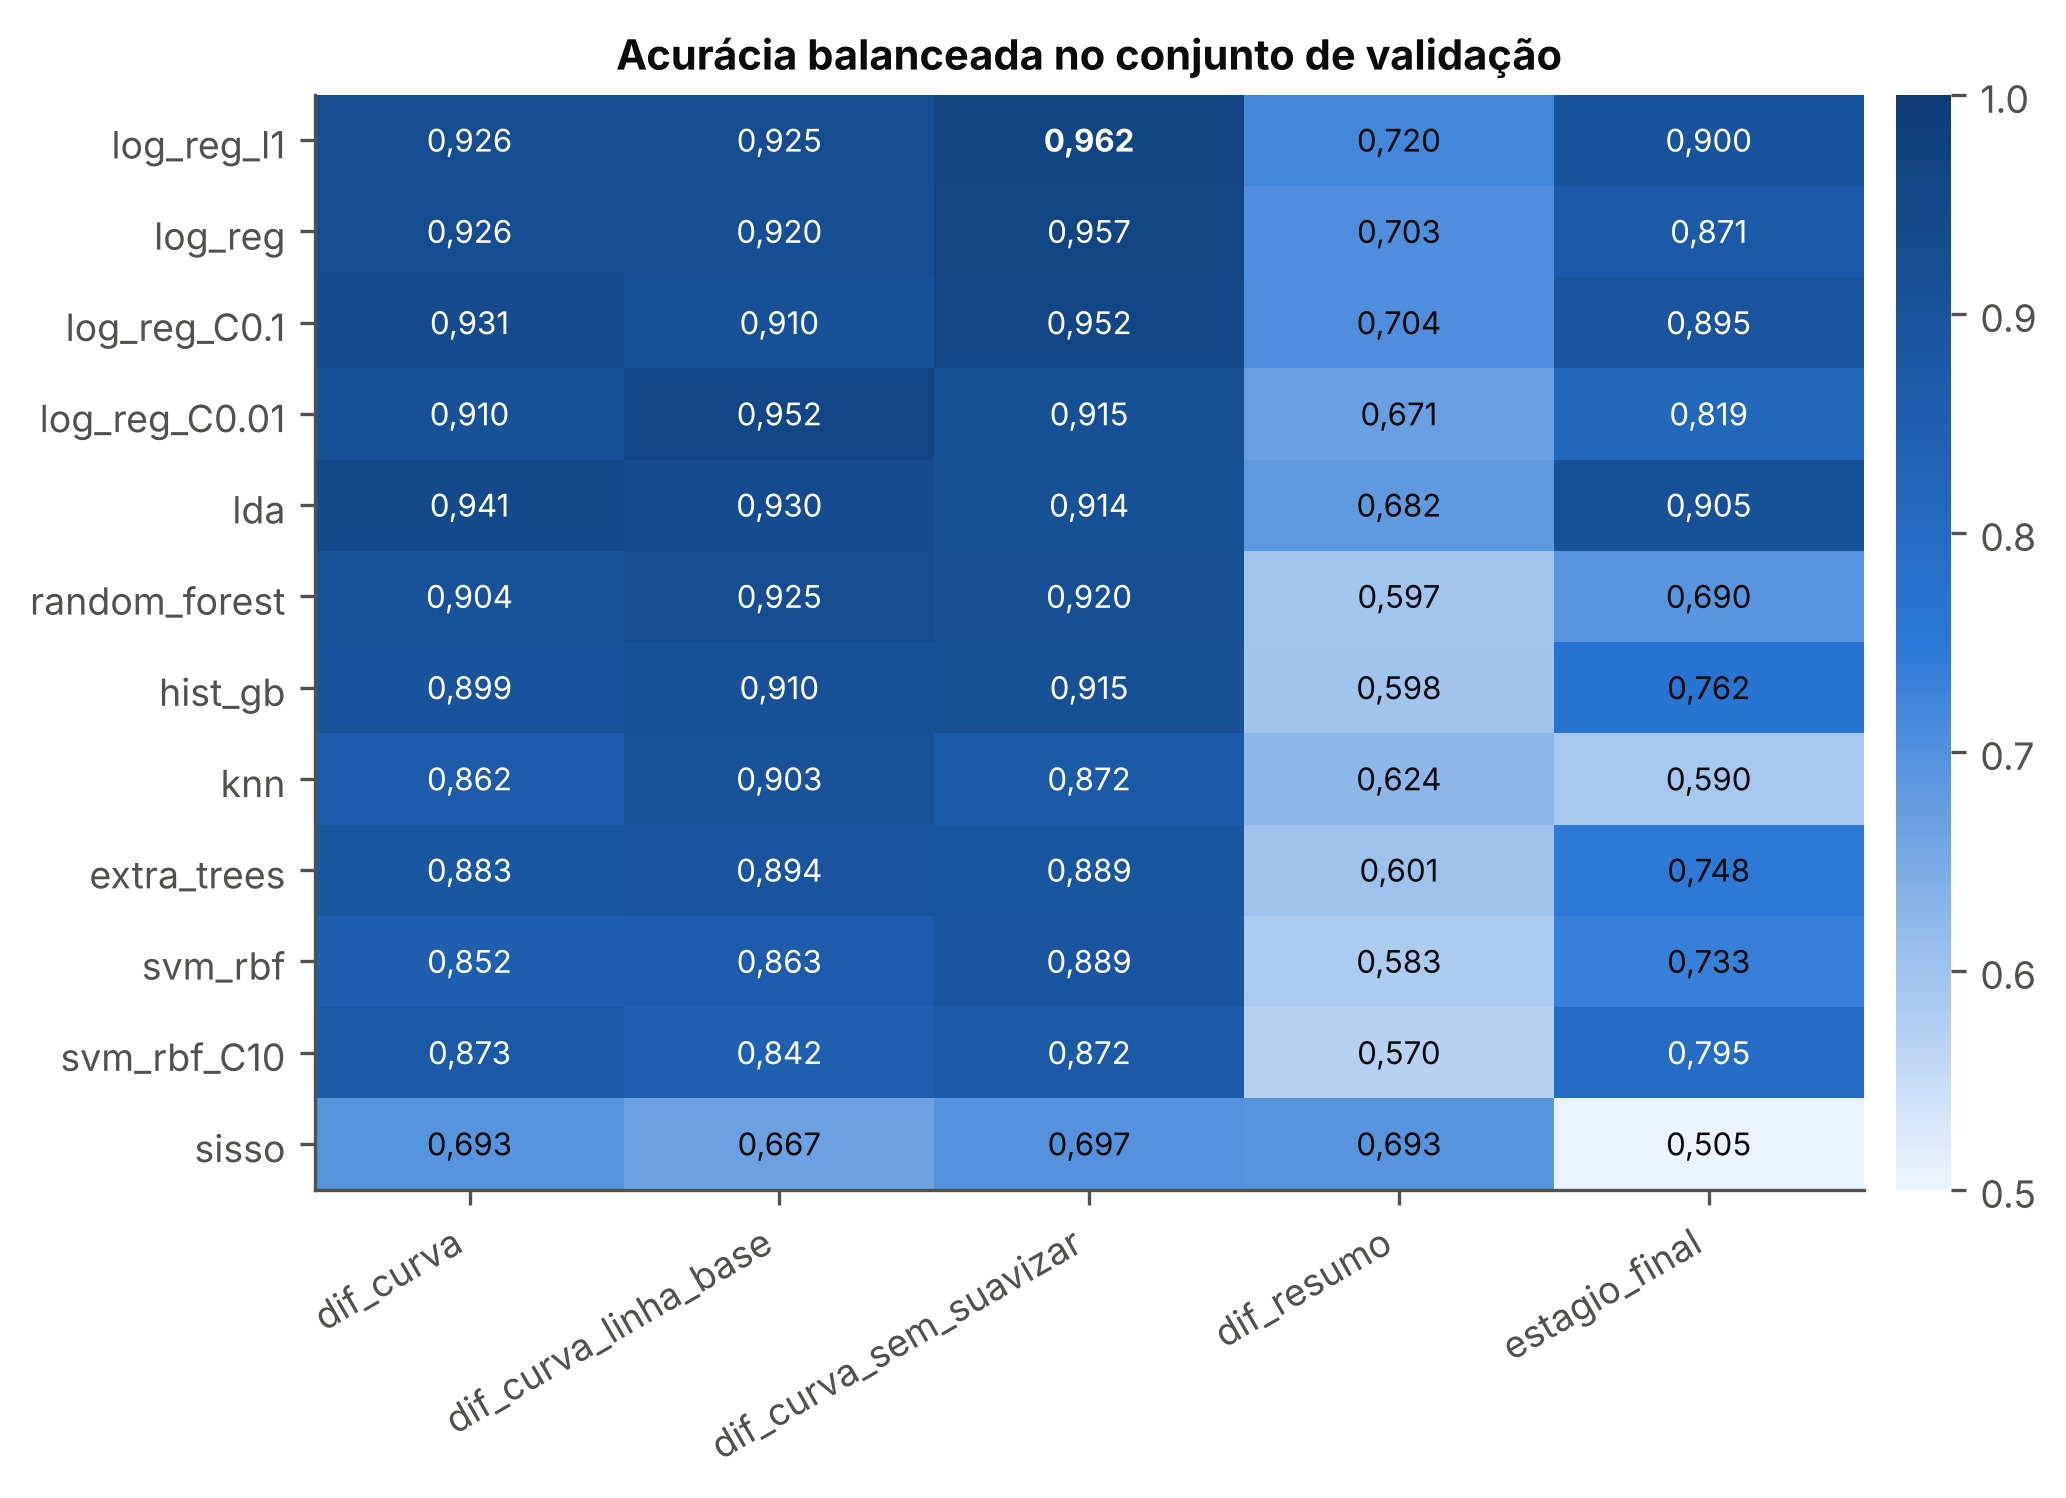

In [8]:
display(Image(pasta_exp / "figuras" / "comparacao_modelos.png", width=780))

## 5. Modelo escolhido

O desempenho de referência é o do **conjunto de teste**: a combinação foi escolhida por ser a melhor na
validação entre dezenas de candidatas, então a acurácia na validação tende a ser otimista. O teste não
participou de nenhuma escolha.

Escolhido: log_reg_l1 [dif_curva_sem_suavizar] — dif_curva sem suavização Savitzky-Golay
Validação cruzada (treino, 100 amostras): AB 0.941 ± 0.014
Validação (50 amostras): AB 0.962 | AUC 0.973
Teste (50 amostras, 128 réplicas): AB 0.916 | sensibilidade 0.860 | especificidade 0.971 | AUC 0.959
Modelo registrado: modelos/20261020-172517


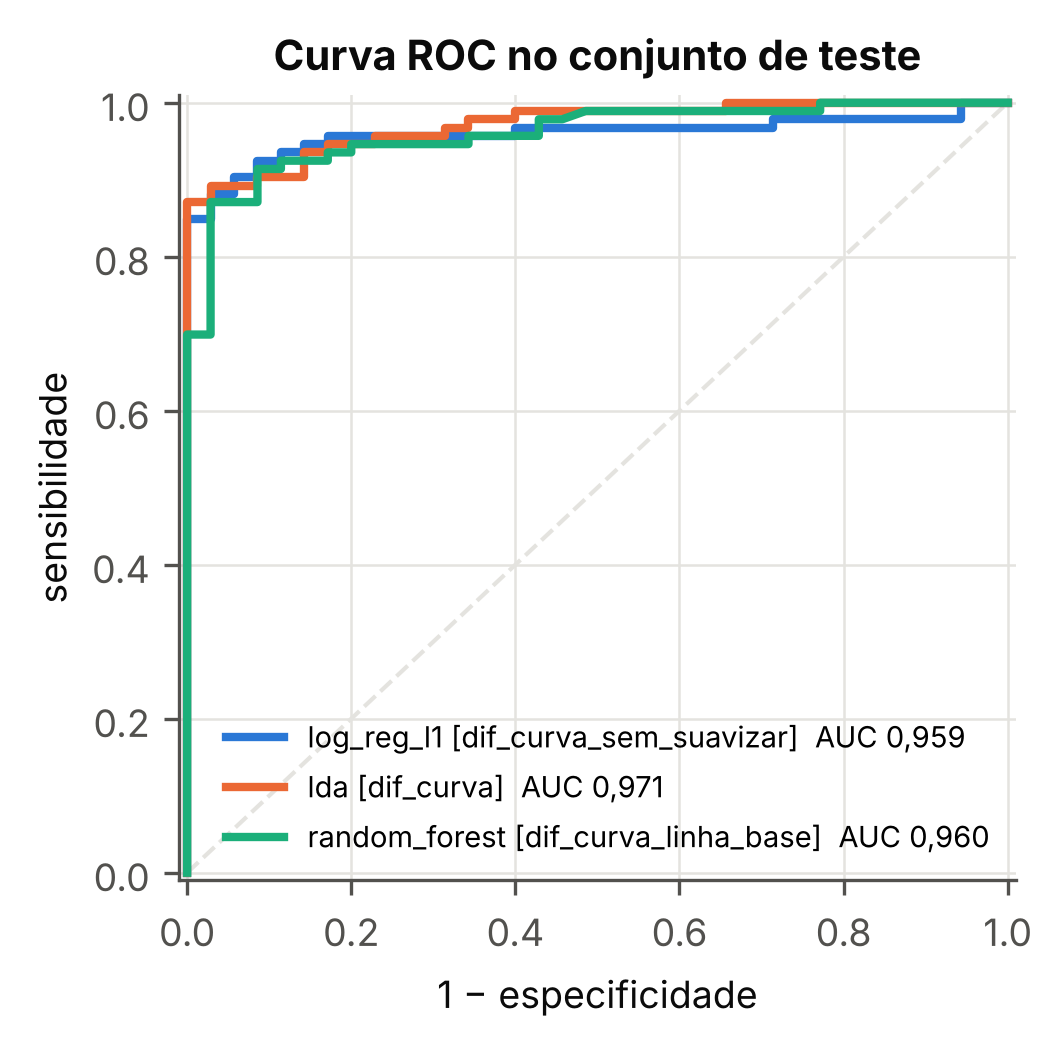

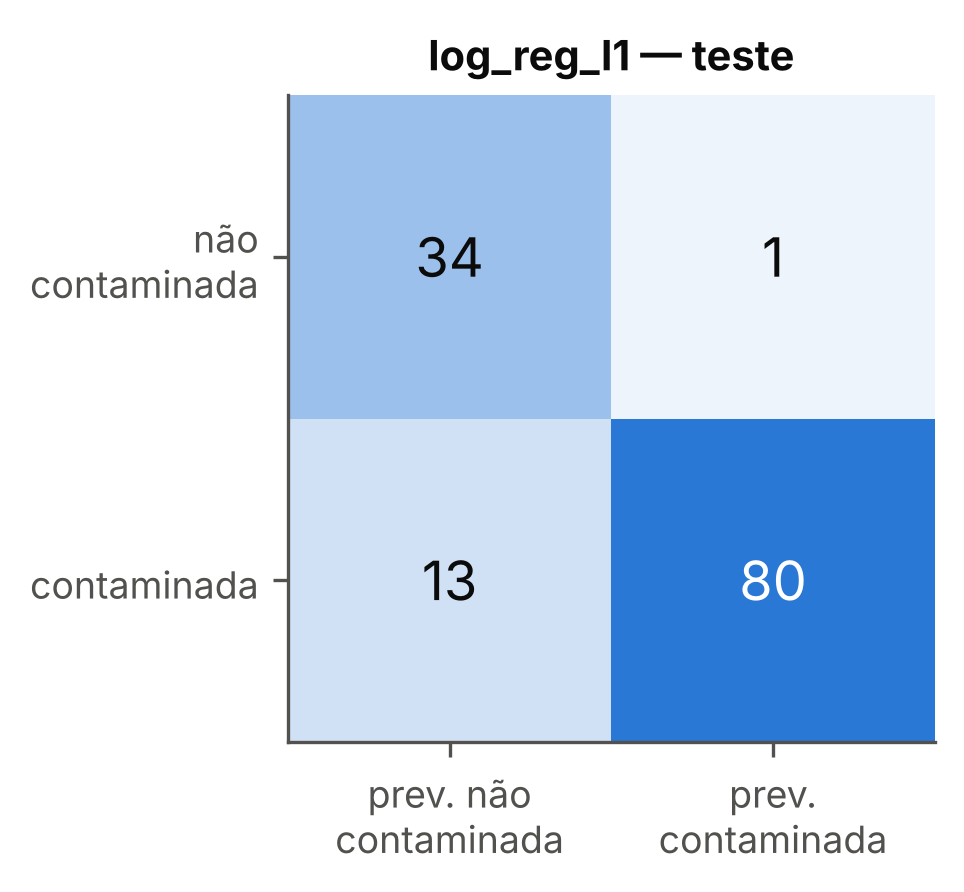

In [9]:
res = r["resumo"]; m = res["melhor"]
print(f"Escolhido: {m['modelo']} [{m['variante']}] — {res['descricao_variante']}")
print(f"Validação cruzada (treino, {res['amostras_treino']} amostras): AB {m['cv_balanced_accuracy']:.3f} ± {m['cv_ba_desvio']:.3f}")
print(f"Validação ({res['amostras_validacao']} amostras): AB {m['val_balanced_accuracy']:.3f} | AUC {m['val_roc_auc']:.3f}")
print(f"Teste ({res['amostras_teste']} amostras, {res['replicas_teste']} réplicas): AB {m['teste_balanced_accuracy']:.3f} | "
      f"sensibilidade {m['teste_sensibilidade']:.3f} | especificidade {m['teste_especificidade']:.3f} | AUC {m['teste_roc_auc']:.3f}")
print(f"Modelo registrado: modelos/{res.get('modelo_registrado')}")
for f in ["roc_teste.png", "matriz_confusao_teste.png"]:
    display(Image(pasta_exp / "figuras" / f, width=360))

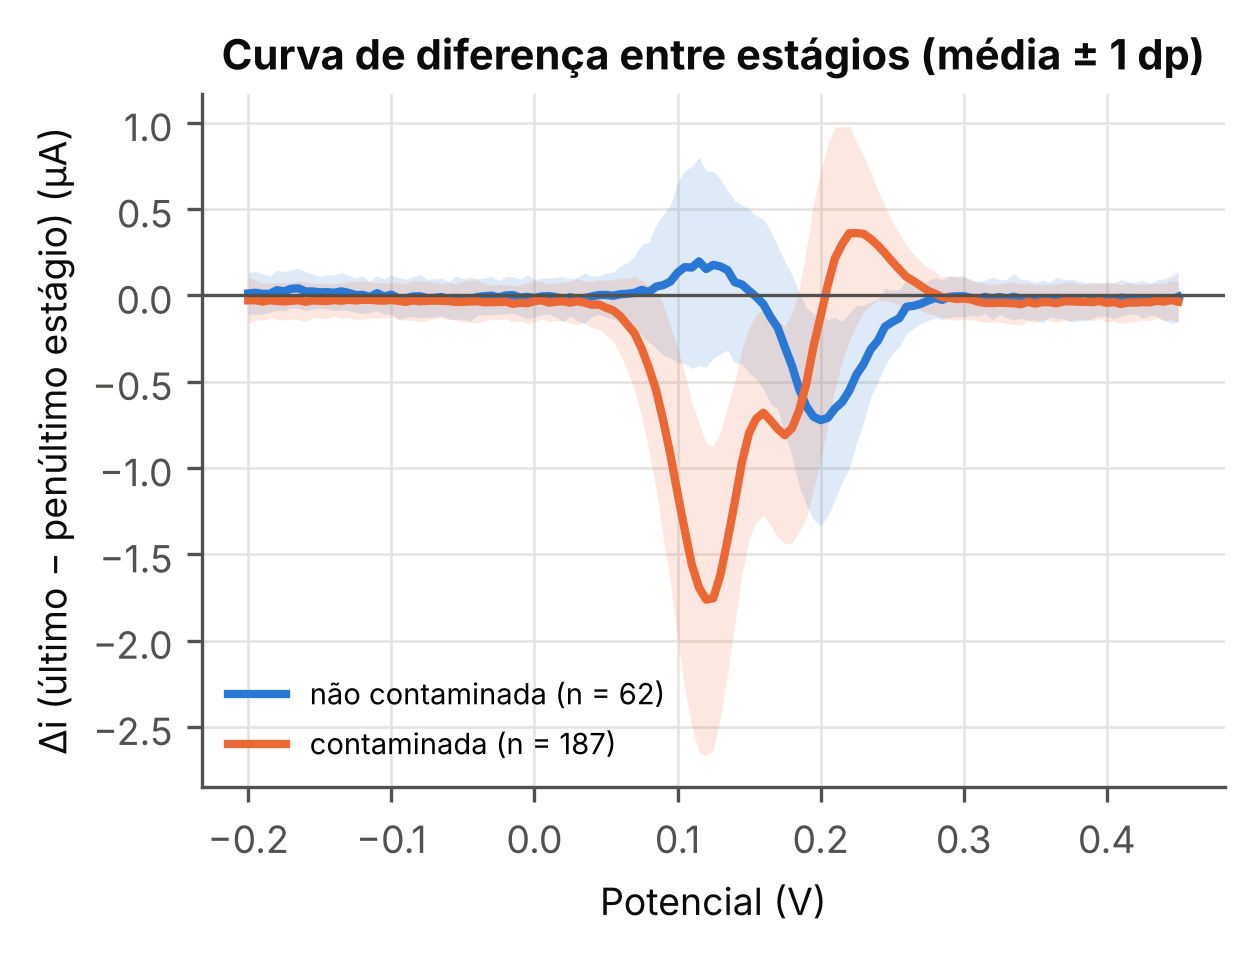

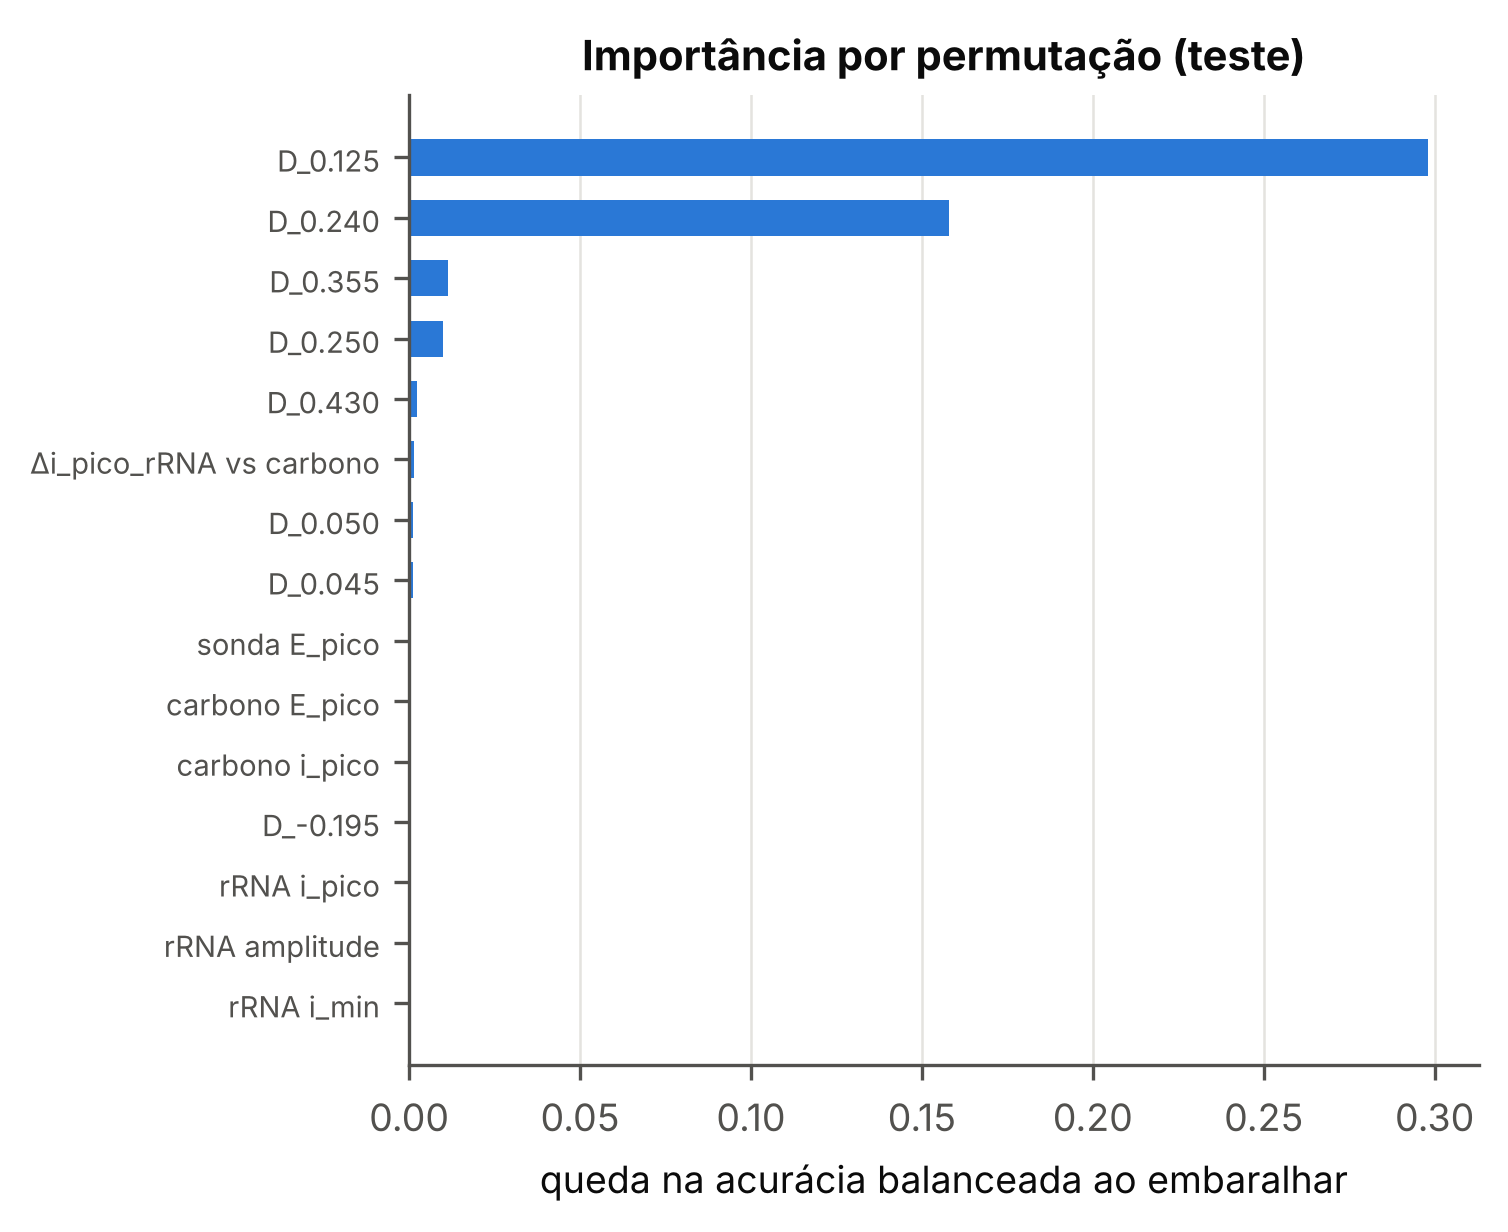

Descritor SISSO (interpretável):
  p(contaminada) = σ(-0.937·[(delta_area_capture_probe_16S_rRNA_vs_carbon_clean-delta_e_pico_capture_probe_16S_rRNA_vs_capture_probe)] -0.756·[delta_i_pico_capture_probe_16S_rRNA_vs_capture_probe] +0.391)  (termos padronizados)


In [10]:
# O que o modelo usa: curva de diferença e importância por permutação no teste
for f in ["curvas_diferenca.png", "importancia.png"]:
    if (pasta_exp / "figuras" / f).exists():
        display(Image(pasta_exp / "figuras" / f, width=480))
print("Descritor SISSO (interpretável):\n ", res.get("formula_sisso"))

### Regressão da carga bacteriana

Nas amostras contaminadas, estima a carga em log10 UFC/mL a partir das mesmas características.
O regressor da mesma representação do classificador vai junto no modelo registrado, e a API
devolve a carga estimada quando a amostra é classificada como contaminada.

,variante,modelo,n_treino,cv_rmse,cv_mae,cv_r2,n_validacao,val_rmse,val_mae,val_r2,n_teste,teste_rmse,teste_mae,teste_r2
0,dif_curva_sem_suavizar,ridge,187,0.954,0.772,0.576,93,0.690,0.520,0.743,93,0.875,0.700,0.693
1,dif_curva_sem_suavizar,pls,187,0.947,0.770,0.582,93,0.693,0.520,0.740,93,0.858,0.694,0.705
2,dif_curva_sem_suavizar,hist_gb,187,1.121,0.907,0.414,93,0.768,0.632,0.681,93,0.994,0.786,0.603
3,dif_curva_sem_suavizar,svr,187,1.047,0.855,0.489,93,0.805,0.639,0.650,93,0.974,0.783,0.619
4,dif_curva_sem_suavizar,extra_trees,187,1.127,0.909,0.408,93,0.855,0.694,0.605,93,1.024,0.803,0.579
5,dif_curva_sem_suavizar,random_forest,187,1.154,0.941,0.379,93,0.877,0.723,0.584,93,1.086,0.857,0.527
6,dif_resumo,ridge,187,1.131,0.917,0.404,93,0.966,0.808,0.495,93,1.078,0.850,0.534
7,dif_resumo,pls,187,1.155,0.929,0.379,93,1.007,0.839,0.452,93,1.094,0.869,0.520
8,dif_resumo,extra_trees,187,1.189,0.949,0.342,93,1.029,0.832,0.428,93,1.167,0.955,0.454
9,dif_resumo,random_forest,187,1.196,0.955,0.334,93,1.074,0.884,0.377,93,1.215,1.009,0.407


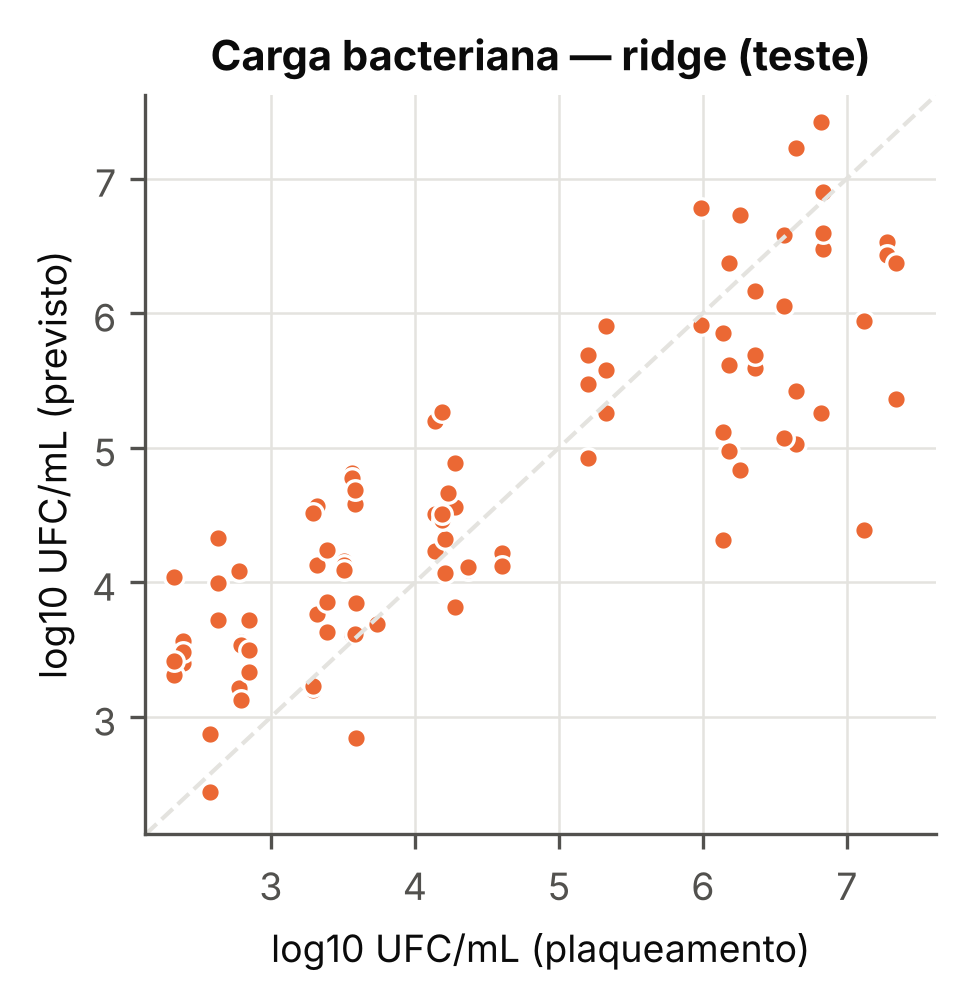

In [11]:
if len(r["regressao"]):
    display(r["regressao"].round(3))
    if (pasta_exp / "figuras" / "regressao_teste.png").exists():
        display(Image(pasta_exp / "figuras" / "regressao_teste.png", width=360))
else:
    print("Sem carga de referência (sample_log10_mean_cfu_ml) suficiente para a regressão.")

## 6. Previsão de uma coleta nova

É exatamente o que a página web (`fiep servir`) faz: lê os arquivos, aplica o controle de qualidade e o
pré-processamento **do modelo registrado** e devolve a classificação, a probabilidade e a carga estimada.
Aqui usamos o conjunto de teste como se fosse uma coleta nova. A resposta final é **por amostra**:
a média das réplicas (eletrodos) aprovadas no controle de qualidade.

In [12]:
from fiep.model import carregar
from fiep.predict import prever, resumo_por_amostra

pacote = carregar("modelos")
saida = prever(divisao.teste, pacote)
db.gravar_predicoes(con, saida, pacote["cartao"], "modelos")
print(saida["resultado"].value_counts().to_string())
avaliadas = saida[saida.status == "avaliada"].dropna(subset=["rotulo_informado"])
if len(avaliadas):
    acerto = ((avaliadas.resultado == "CONTAMINADA").astype(int) == avaliadas.rotulo_informado).mean()
    print(f"\nAcerto nas réplicas avaliadas com rótulo: {acerto:.1%}")
por_amostra = resumo_por_amostra(saida)
ok = por_amostra.dropna(subset=["rotulo_informado"])
ok = ok[ok.resultado.isin(["CONTAMINADA", "NÃO CONTAMINADA"])]
print(f"Acerto por amostra (média das réplicas): {((ok.resultado == 'CONTAMINADA').astype(int) == ok.rotulo_informado).mean():.1%} em {len(ok)} amostras")
por_amostra.head(12)

resultado
CONTAMINADA        81
NÃO CONTAMINADA    47
REPETIR MEDIÇÃO    25
SEM PREVISÃO       22

Acerto nas réplicas avaliadas com rótulo: 89.1%
Acerto por amostra (média das réplicas): 96.0% em 50 amostras


,sample_id,resultado,prob_contaminada,replicas_avaliadas,replicas_total,concordancia,log10_ufc_ml_estimado,nivel_contaminacao,rotulo_informado
0,EC_002,CONTAMINADA,0.9330,3,3,1.000,5.89,detectada,1.0
1,EC_005,CONTAMINADA,0.7912,3,3,0.667,4.79,detectada,1.0
2,EC_010,CONTAMINADA,1.0000,2,3,1.000,6.34,detectada,1.0
3,EC_017,CONTAMINADA,0.6661,3,3,0.667,4.14,detectada,1.0
4,EC_018,CONTAMINADA,0.9929,3,3,1.000,4.65,detectada,1.0
5,EC_029,CONTAMINADA,0.9798,2,3,1.000,3.65,detectada,1.0
6,EC_031,CONTAMINADA,0.9967,3,3,1.000,5.90,detectada,1.0
7,EC_041,NÃO CONTAMINADA,0.1143,3,3,1.000,NaN,não detectada,0.0
8,EC_043,CONTAMINADA,1.0000,1,3,1.000,6.73,detectada,1.0
9,EC_047,NÃO CONTAMINADA,0.1885,3,3,0.667,NaN,não detectada,0.0


## Conclusões e próximos passos

- A representação pela **diferença entre estágios** do mesmo eletrodo é a que separa as classes; o estágio
  final isolado e os descritores resumidos rendem bem menos. O protocolo de coleta precisa garantir os
  três estágios por eletrodo.
- O **controle de qualidade** automático impede que medições com sobrecarga ou potencial fora do aplicado
  entrem no treino.
- O modelo escolhido está registrado em `modelos/` e é usado pela página web (`fiep servir`);
  as figuras e tabelas deste experimento alimentam o artigo (`fiep experimento --artigo`).
- Próximo passo: substituir o conjunto de demonstração pelos dados reais em `dados/` e, quando houver,
  colocar uma coleta independente (outra empresa ou outro lote) em `dados/teste/` (validação externa, objetivo 7).

In [13]:
con.close()